<h1> Loading in the data </h1>

* first load in and process the nuclei data similar to the single cell data
* this will be done following what MA did to be consistent rather than run through seurat
---

In [ ]:
import scanpy as sc
import numpy as np
import anndata as ad

In [ ]:
sample_list = np.array(["WT", "mdx", "TG"])
data_dir = "_filtered_feature_bc_matrix.h5"
sample_dir = sample_list+data_dir

# initiate empty list
adata_list = []

# load in dataset
for file in sample_dir:
    
    # Read 10x H5 file
    adata = sc.read_10x_h5(file)

    # Add metadata by splitting by the "_" symbol
    # first index is returned (i.e., the genotype name)
    adata.obs['sample_id'] = file.split("_")[0]

    # Ensure obs_names are unique before concatenating
    adata.var["original_names"] = adata.var_names
    adata.obs_names_make_unique()
    adata.var_names_make_unique()

    adata_list.append(adata)

## optional do it all together
adata_joined = ad.concat(adata_list, label="sample_id", keys=sample_list)

In [ ]:
adata_joined.obs["sample_id"].unique()

---
<h1>Quality control</h1>

* note mt counts are low in nuclei

In [ ]:
sc.pp.calculate_qc_metrics(adata_joined, inplace=True, log1p=True)

# for dataset in adata_list:
#     sc.pp.calculate_qc_metrics(dataset, inplace=True, log1p=True)

# for dataset in adata_list:
#     sc.pl.violin(
#         dataset,
#         ["n_genes_by_counts", "total_counts"],
#         jitter=0.4,
#     multi_panel=True,
#     )

sc.pl.violin(adata_joined, ["n_genes_by_counts", "total_counts"],
             jitter=0.4, multi_panel=True,
             groupby="sample_id")

In [ ]:
sc.pl.scatter(adata_joined, "total_counts", "n_genes_by_counts", color="sample_id"), 

# for dataset in adata_list:
#     sc.pl.scatter(adata, "total_counts", "n_genes_by_counts")

In [ ]:
sc.pp.filter_cells(adata_joined, min_genes=200)
sc.pp.filter_genes(adata_joined, min_cells=3)
sc.pp.filter_cells(adata_joined, max_genes=6000)

sc.pl.violin(adata_joined, ["n_genes_by_counts", "total_counts"], multi_panel=True, groupby="sample_id")

# for dataset in adata_list:
#     sc.pp.filter_cells(dataset, min_genes=200)
#     sc.pp.filter_genes(dataset, min_cells=3)
#     sc.pp.filter_cells(dataset, max_genes=6000)

# for dataset in adata_list:
#     sc.pl.violin(
#         dataset,
#         ["n_genes_by_counts", "total_counts"],
#         jitter=0.4,
#     multi_panel=True,
#     )

In [ ]:
# save original counts
adata_joined.layers["counts"] = adata_joined.X.copy()
sc.pp.normalize_total(adata_joined)
sc.pp.log1p(adata_joined)
sc.pp.highly_variable_genes(adata_joined, n_top_genes=2000)
sc.pl.highly_variable_genes(adata_joined)

# for dataset in adata_list:

#     dataset.layers["counts"] = dataset.X.copy()

#     # Normalizing to median total counts
#     sc.pp.normalize_total(dataset)

#     # Logarithmize the data
#     sc.pp.log1p(dataset)
    
#     # highly variable genes
#     sc.pp.highly_variable_genes(dataset, n_top_genes=2000)

#     sc.pl.highly_variable_genes(dataset)

In [ ]:
## PCA
sc.tl.pca(adata_joined)
sc.pl.pca_variance_ratio(adata_joined, n_pcs=50, log=True)
sc.pl.pca(adata_joined, color="sample_id")

# for dataset in adata_list:
#     sc.tl.pca(dataset)
#     sc.pl.pca_variance_ratio(dataset, n_pcs=50, log=True)
#     sc.pl.pca(dataset)

In [ ]:
## umap
sc.pp.neighbors(adata_joined)
sc.tl.umap(adata_joined)

# for dataset in adata_list:
#     sc.pp.neighbors(dataset)
#     sc.tl.umap(dataset)
#     sc.pl.umap(dataset)

---
<h1>Plotting and clustering</h1>

In [ ]:
sc.pl.umap(adata_joined, color="sample_id", size=2)

In [ ]:
for sample in sample_list:
    sc.pl.umap(adata_joined[adata_joined.obs["sample_id"] == sample], size=2)

In [ ]:
res_list = np.arange(0.1, 1.1, 0.1)
for res in res_list:
    sc.tl.leiden(adata_joined, flavor="igraph", n_iterations=2, resolution=res,
                 key_added=f"leiden_res_{res:.1f}")

In [ ]:
adata_joined.uns_keys

In [ ]:
sc.pl.umap(
    adata_joined,
    color=["leiden_res_0.1", "leiden_res_0.2", "leiden_res_0.3",
           "leiden_res_0.4", "leiden_res_0.5", "leiden_res_0.6",
           "leiden_res_0.7", "leiden_res_0.8", "leiden_res_0.9", "leiden_res_1.0"],
    legend_loc="on data",
    ncols=3
)

In [ ]:
# remove all these, not needed
del adata_joined.uns['leiden_res_0.1']
del adata_joined.uns['leiden_res_0.2']
del adata_joined.uns['leiden_res_0.3']
del adata_joined.uns['leiden_res_0.4']
del adata_joined.uns['leiden_res_0.5']
del adata_joined.uns['leiden_res_0.6']
del adata_joined.uns['leiden_res_0.7']
del adata_joined.uns['leiden_res_0.8']
del adata_joined.uns['leiden_res_1.0']
del adata_joined.uns['leiden_res_0.1_colors']
del adata_joined.uns['leiden_res_0.2_colors']
del adata_joined.uns['leiden_res_0.3_colors']
del adata_joined.uns['leiden_res_0.4_colors']
del adata_joined.uns['leiden_res_0.5_colors']
del adata_joined.uns['leiden_res_0.6_colors']
del adata_joined.uns['leiden_res_0.7_colors']
del adata_joined.uns['leiden_res_0.8_colors']
del adata_joined.uns['leiden_res_1.0_colors']

del adata_joined.obs["leiden_res_0.1"]
del adata_joined.obs["leiden_res_0.2"]
del adata_joined.obs["leiden_res_0.3"]
del adata_joined.obs["leiden_res_0.4"]
del adata_joined.obs["leiden_res_0.5"]
del adata_joined.obs["leiden_res_0.6"]
del adata_joined.obs["leiden_res_0.7"]
del adata_joined.obs["leiden_res_0.8"]
del adata_joined.obs["leiden_res_1.0"]

In [ ]:
## cluster genes
sc.tl.rank_genes_groups(adata_joined, groupby="leiden_res_0.9", method="wilcoxon")

In [ ]:
sc.pl.rank_genes_groups_dotplot(adata_joined, groupby="leiden_res_0.9", standard_scale="var", n_genes=5)

In [ ]:
# put genes into data frame
all_cluster_markers = sc.get.rank_genes_groups_df(
    adata_joined,
    group=None,
    log2fc_min=1, 
    pval_cutoff = 0.05
    )

In [ ]:
## all genes
all_cluster_markers.to_excel("all_cluster_markers.xlsx") # all genes

# filter out duuplicates
all_cluster_markers_no_dup = all_cluster_markers.drop_duplicates(subset=["names"])
all_cluster_markers_no_dup.to_excel("all_cluster_markers_filtered.xlsx")

In [ ]:
# save top genes
top_cluster_markers = all_cluster_markers.groupby("group").head(100)
top_cluster_markers.to_excel(excel_writer="cluster gene markers.xlsx")

In [ ]:
sample_list = ["WT", "mdx", "TG"]
plot_umap = [] # list
for sample in sample_list:
    fig = sc.pl.umap(adata_joined[adata_joined.obs["sample_id"] == sample], 
               size=2, 
               color=["leiden_res_0.9"],
               legend_loc = "on data",
               show=False,
               return_fig=True)
    plot_umap.append(fig)
    plt.close(fig)

In [ ]:
import matplotlib.pyplot as plt

In [ ]:
# save plots
for sample, fig in zip(sample_list, plot_umap):

    filename = f'Figures/{sample}_umap.tiff'
    fig.savefig(filename, dpi=600, format="tiff", bbox_inches="tight")
    print(f'Saved {filename}')
    
    plt.close(fig)

In [ ]:
adata_joined.obs.head()

In [ ]:
sc.pl.violin(adata_joined, ["Pax3"], multi_panel=True, groupby="leiden_res_0.9", size=0)

In [ ]:
vln_plt = sc.pl.violin(adata_joined, ["Col1a1"], 
                       multi_panel=True, 
                       groupby="leiden_res_0.9", show=False)

In [ ]:
vln_plt[0].figure.savefig('Figures/Cd82.tiff', dpi=600)
plt.close()

In [ ]:
for i, fig in enumerate(vln_plot):
    filename = f'Figures/vln_{i+1}.tiff'
    fig.savefig(filename, dpi=600, format="tiff", bbox_inches="tight")
    print(f'Saved {filename}')
    
    plt.close(fig)

In [ ]:
# # save for now, annotate later
# adata_joined.write_h5ad("processed_notannotated.h5ad")

In [ ]:
adata_joined = ad.read_h5ad("processed_notannotated.h5ad")

---
<h1>FAPs</h1>

In [ ]:
# for differential expression, comparing between genotypes
adata_joined.obs["comparisons"] = adata_joined.obs["sample_id"].astype("category")

In [ ]:
# subset FAPs
FAPs_clusters = ["9", "10", "17"]
FAPs_ID = adata_joined.obs["leiden_res_0.9"].isin(FAPs_clusters)
FAPs = adata_joined[FAPs_ID, :].copy()

In [ ]:
# save FAPs for later use (these are from nuclei)
FAPs.write_h5ad("FAPs.h5ad")

In [ ]:
sc.pl.umap(FAPs, color="leiden_res_0.9", size=2)

In [ ]:
sample_list = ["WT", "mdx", "TG"]
for sample in sample_list:
    sc.pl.umap(FAPs[FAPs.obs["sample_id"] == sample], size=50, color="leiden_res_0.9", legend_loc="on data")

* note the shift to cluster 17 (non progenitors) in mdx and mdx-TG
* though mdx-TG appears to have more Pi16<sup>+</sup> cells
* subclustering might shwo that small population that slightly separates from 17 as Postn<sup>+</sup>

In [ ]:
for sample in sample_list:
    sc.pl.umap(FAPs[FAPs.obs["sample_id"] == sample], 
               color="Postn", 
               size=50, 
               vmin=0, 
               vmax=4)

<em>voilà</em>

In [ ]:
# pairwise comparisons
# keeping all genes, but filtering later based on log2fc and p-value
sc.tl.rank_genes_groups(adata=FAPs, groupby='comparisons', method='wilcoxon', groups=['mdx'], reference='WT')
mdxvsWT = sc.get.rank_genes_groups_df(FAPs, group='mdx')
mdxvsWT.to_excel("mdxvsWT.xlsx")

sc.tl.rank_genes_groups(adata=FAPs, groupby='comparisons', method='wilcoxon', groups=['TG'], reference='WT')
TGvsWT = sc.get.rank_genes_groups_df(FAPs, group='TG')
TGvsWT.to_excel("TGvsWT.xlsx")

sc.tl.rank_genes_groups(adata=FAPs, groupby='comparisons', method='wilcoxon', groups=['TG'], reference='mdx')
TGvsmdx = sc.get.rank_genes_groups_df(FAPs, group='TG')
TGvsmdx.to_excel("TGvsmdx.xlsx")

In [ ]:
# differential expression
sc.tl.rank_genes_groups(FAPs, 
                        groupby='comparisons',
                        reference='rest', 
                        method='wilcoxon')

In [ ]:
# unique genes
WT_genes = sc.get.rank_genes_groups_df(FAPs, group='WT')
mdx_genes = sc.get.rank_genes_groups_df(FAPs, group='mdx')
TG_genes = sc.get.rank_genes_groups_df(FAPs, group='TG')

In [ ]:
WT_genes.to_excel("FAPS_WT_genes.xlsx")
mdx_genes.to_excel("FAPS_mdx_genes.xlsx")
TG_genes.to_excel("FAPS_TG_genes.xlsx")

In [ ]:
FAPs.obs["leiden_res_0.9"]

In [ ]:
for cluster in FAPs_clusters:
    sc.pl.violin(FAPs[FAPs.obs["leiden_res_0.9"] == cluster], ["Tead4"], groupby="sample_id", size=2)

---
<h1> Some metrics </h1>

In [ ]:
print(adata_joined.obs.columns)

In [ ]:
mean_counts_per_group = adata_joined.obs.groupby('sample_id')['total_counts'].mean()
mean_genes_per_group = adata_joined.obs.groupby('sample_id')['n_genes_by_counts'].mean()
print(mean_counts_per_group)
print(mean_genes_per_group)
mean_counts_per_group.to_excel("mean_counts_per_group.xlsx")
mean_genes_per_group.to_excel("mean_genes_per_group.xlsx")


In [ ]:
median_counts_per_group = adata_joined.obs.groupby('sample_id')['total_counts'].median()
median_genes_per_group = adata_joined.obs.groupby('sample_id')['n_genes_by_counts'].median()
median_counts_per_group.to_excel("median_counts_per_group.xlsx")
median_genes_per_group.to_excel("median_genes_per_group.xlsx")

---
<h1> Annotation and number of cells </h1>

In [ ]:
adata_joined = ad.read_h5ad("processed_notannotated.h5ad")

In [ ]:
sample_list = ["WT", "mdx", "TG"]
for sample in sample_list:
    sc.pl.umap(adata_joined[adata_joined.obs["sample_id"] == sample], size=2, color="Pdgfra")

In [ ]:
cluster_annotations = {
    "0": "Type 2b",
    "1": "Type 2b",
    "2": "Type 2b",
    "3": "Type 2b",
    "4": "Type 2a/x",
    "5": "Type 2b",
    "6": "Type 2a/x",
    "7": "MTJ",
    "8": "ECs",
    "9": "FAPs",
    "10": "FAPs",
    "11": "Type 2b",
    "12": "Regenerating myonuclei",
    "13": "Smooth muscle",
    "14": "Immune cells",
    "15": "SCs",
    "16": "NMJ",
    "17": "FAPs",
    "18": "Type 2a/x",
    "19": "ECs",
    "20": "Tenocyotes",
    "21": "Adipocytes",
    "22": "Schwann cells",
}

adata_joined.obs['cell_type'] = (
    adata_joined.obs['leiden_res_0.9']
    .map(cluster_annotations)
    .astype('category') # Convert to category type for efficient storage and plotting
)


In [ ]:
for sample in sample_list:
    sc.pl.umap(adata_joined[adata_joined.obs["sample_id"] == sample], size=2, color="cell_type", legend_loc="on data")

In [ ]:
adata_joined.write_h5ad("processed_annotated.h5ad")

In [ ]:
genotype_proportions = (
    adata_joined.obs.groupby('sample_id')['cell_type']
    .value_counts(normalize=True)
    .unstack(fill_value=0)
) * 100

print(genotype_proportions.head())

In [ ]:
genotype_proportions.to_excel("genotype_proportions.xlsx")

---
<h2> cell data </h2>

In [ ]:
cell_data = ad.read_h5ad("merged_cell.h5ad")

In [ ]:
print(cell_data.obs.columns)

In [ ]:
sample_list = ["WT", "mdx", "mdx-TG"]
for sample in sample_list:
    sc.pl.umap(cell_data[cell_data.obs["condition"] == sample], size=2, color="leiden", legend_loc="on data")

In [ ]:
genotype_counts = (
    cell_data.obs.groupby('condition')['leiden']
    .value_counts(normalize=False)
    .unstack(fill_value=0)
)

print(genotype_proportions.head())

In [ ]:
genotype_counts.to_excel("genotype_counts_cell.xlsx")

## cyotkine plots

In [8]:
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
import pandas as pd
import numpy as np
import os

#  Global font settings 
mpl.rcParams['font.family'] = 'Arial'
mpl.rcParams['font.size'] = 8
mpl.rcParams['svg.fonttype'] = 'none'  # keep text editable

# mpl.rcParams['path.simplify'] = True
# mpl.rcParams['path.simplify_threshold'] = 1.0  # max simplification, 0 = off
# mpl.rcParams['agg.path.chunksize'] = 10000

# colors
genotype_colors = {
    "WT": "black",
    "mdx": "red",
    "mdx-TG": "blue"
}

In [ ]:
cell_types = cell_data.obs['leiden'].unique().tolist()
genes = ["IL1A", "CCL2", "CXCL9", "CXCL10", "CCL11", "TGFB1"]

In [ ]:
outdir = "Figures/cytokine_violin_plots_svg"
os.makedirs(outdir, exist_ok=True)
for cell in cell_types:
    subset = cell_data[cell_data.obs['leiden'] == cell]
    
    if subset.n_obs == 0:
        continue
    
    ax = sc.pl.violin(
        subset,
        keys=genes,
        groupby="condition",
        show=False,
        size=0,
        stripplot=False,
        palette=genotype_colors
    )
    
    fig = plt.gcf()
    fig.suptitle(f"Cell type: {cell}", fontsize=8, fontfamily='Arial', y=1.05)
    
    for a in fig.get_axes():
        a.set_box_aspect(1)  
        a.tick_params(labelsize=8)
        a.xaxis.label.set_size(8)
        a.yaxis.label.set_size(8)
        a.xaxis.label.set_fontfamily('Arial')
        a.yaxis.label.set_fontfamily('Arial')
        a.title.set_fontsize(8)
        a.title.set_fontfamily('Arial')
        for label in a.get_xticklabels() + a.get_yticklabels():
            label.set_fontfamily('Arial')
            label.set_fontsize(8)
    
    fig.set_size_inches(len(genes) * 1.2, 1)
    plt.tight_layout()
    safe_name = str(cell).replace("/", "_").replace(" ", "_")
    fig.savefig(f"{outdir}/violin_{safe_name}.svg", format='svg', bbox_inches='tight')
    plt.show()
    plt.close(fig)

C:\Users\dphel\AppData\Local\Temp\ipykernel_12052\2482228961.py:28: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


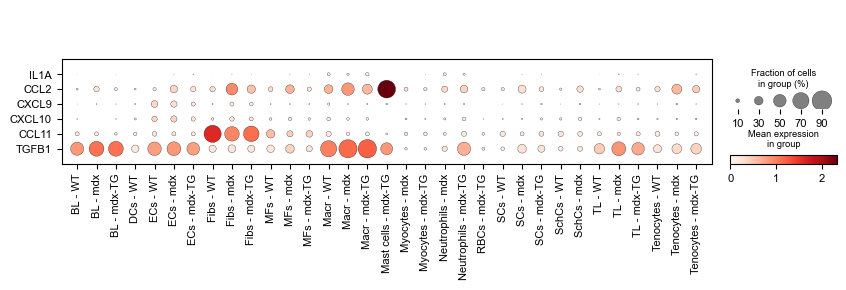

In [18]:
# cell type and genotype
cell_data.obs['celltype_condition'] = (
    cell_data.obs['leiden'].astype(str) + " - " + cell_data.obs['condition'].astype(str)
)

# # optional: control row order (otherwise alphabetical)
# order = sorted(cell_data.obs['celltype_condition'].unique())

ax = sc.pl.dotplot(
    cell_data,
    var_names=genes,
    groupby='celltype_condition',
    # categories_order=order,
    show=False,
    swap_axes=True,
    # standard_scale='var',  # normalizes each gene 0-1 across groups; remove if you want raw scale
)

fig = plt.gcf()

for a in fig.get_axes():
    a.tick_params(labelsize=8)
    for label in a.get_xticklabels() + a.get_yticklabels():
        label.set_fontfamily('Arial')
        label.set_fontsize(8)

fig.set_size_inches(10, 2)
plt.tight_layout()
# outdir = "Figures"
# os.makedirs(outdir, exist_ok=True)
# fig.savefig(f"{outdir}/dotplot_celltype_condition.svg", format='svg', bbox_inches='tight')
plt.show()